In [4]:
# data 
import numpy as np
import matplotlib.pyplot as plt

def get_column(data, index):
    result = [row[index] for row in data]
    return result

data = np.genfromtxt('data/data.csv', delimiter=',').tolist()

x_data = get_column(data, 0)
y_data = get_column(data, 1)

N = len(x_data)

print(f'areas: {x_data}')
print(f'prices: {y_data}')
print(f'data_size: {N}')

areas: [6.7, 4.6, 3.5, 5.5]
prices: [9.1, 5.9, 4.6, 6.7]
data_size: 4


In [5]:
# forward
def predict(x, w, b):
    return x * w + b

# compute gradient
def gradient(y_hat, y, x):
    dw = x * (y_hat - y) / abs(y_hat - y)
    db = (y_hat - y) / abs(y_hat - y)
    return dw, db

# update weights
def update_weights(w, b, dw, db, lr):
    w_new = w - lr * dw
    b_new = b - lr * db
    return w_new, b_new



In [6]:
# init weights
b = 0.04
w = -0.34
lr = 0.01

# parameters
epoch_max = 20
losses = []

for epoch in range(epoch_max):
    # for an epoch
    for i in range(N):

        # get a sample
        x = x_data[i]
        y = y_data[i]

        # predict y_hat
        y_hat = predict(x, w, b)

        # compute loss
        loss = abs(y_hat - y)

        # for debug
        losses.append(loss)

        # compute gradient
        dw, db = gradient(y_hat, y, x)

        # update weights
        w, b = update_weights(w, b, dw, db, lr)
print(f'w = {w}, b = {b}')

w = 1.1859999999999986, b = 0.34000000000000014


In [7]:
area_real = 6
w = 1.221
b = 0.225

predicted_price = area_real * w + b
print('predicted_prcie : ', predicted_price)

predicted_prcie :  7.551


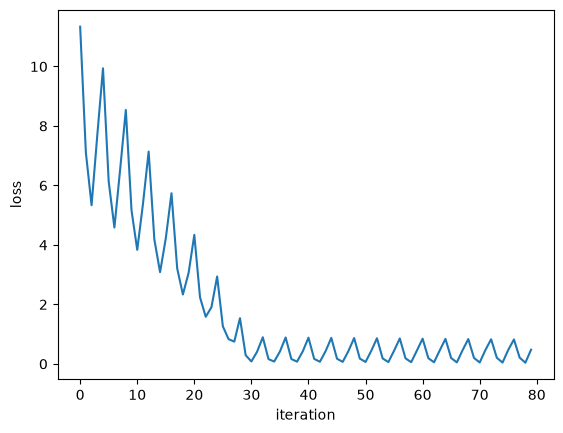

In [8]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel('iteration')
plt.ylabel('loss')
plt.show()

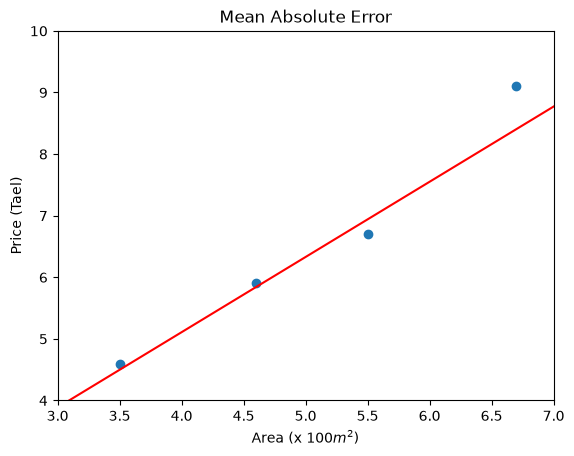

In [9]:
x_data = range(2, 8)
y_data = [x * w + b for x in x_data]

plt.plot(x_data, y_data, 'r')

data = np.genfromtxt('data/data.csv', delimiter=',').tolist()

areas = get_column(data, 0)
prices = get_column(data, 1)
plt.scatter(areas, prices)

plt.xlabel('Area (x 100$m^2$)')
plt.ylabel('Price (Tael)')
plt.title('Mean Absolute Error')

plt.xlim(3, 7)
plt.ylim(4, 10)
plt.show()